In [20]:
import requests
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

In [3]:
import requests

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
output_name = "course_lead_scoring_2026.csv"

# Send a GET request to the URL
response = requests.get(url)

# Check if the request was successful
if response.status_code == 200:
    # Open a local file in write-binary mode and save the content
    with open(output_name, "wb") as file:
        file.write(response.content)
    print(f"File successfully downloaded and saved as {output_name}")
else:
    print(f"Failed to download file. Status code: {response.status_code}")

File successfully downloaded and saved as course_lead_scoring_2026.csv


In [4]:
df = pd.read_csv("course_lead_scoring_2026.csv")

In [5]:
categorical = list(df.dtypes[df.dtypes == 'object'].index)

for c in categorical:
    df[c] = df[c].fillna("NA")
numerical = list(df.dtypes[df.dtypes != 'object'].index)

for c in numerical:
    df[c] = df[c].fillna(0)

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [7]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [8]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [9]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [10]:
numerical_iv = list(df_train.dtypes[df_train.dtypes != 'object'].index)

In [11]:
for col in ["lead_score","number_of_courses_viewed","interaction_count","annual_income"]:
    dv = DictVectorizer(sparse=False)
    train_dict = df_train[[col]].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    print(f"AUC score for {col}")
    print(roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]))

AUC score for lead_score
0.7882254810906102
AUC score for number_of_courses_viewed
0.7229894623989618
AUC score for interaction_count
0.7649203047563227
AUC score for annual_income
0.6081977776250831


In [12]:
dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical+numerical_iv].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)
val_dict = df_val[categorical + numerical_iv].to_dict(orient='records')
X_val = dv.transform(val_dict)
print(f"AUC score for this model")
print(round(roc_auc_score(y_val, model.predict_proba(X_val)[:, 1]),3))

AUC score for this model
0.732


In [14]:
y_pred = model.predict_proba(X_val)[:, 1]

In [43]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    p = tp / (tp + fp)
    r = tp / (tp + fn)
    f1 = 2 * ((p*r)/(p+r))
    
    scores.append((t, p, r,f1))

C:\Users\PC\AppData\Local\Temp\ipykernel_11208\465403241.py:17: RuntimeWarning: invalid value encountered in scalar divide
  p = tp / (tp + fp)


In [44]:
columns = ['threshold', 'p', 'r','f1']
df_scores = pd.DataFrame(scores, columns=columns)


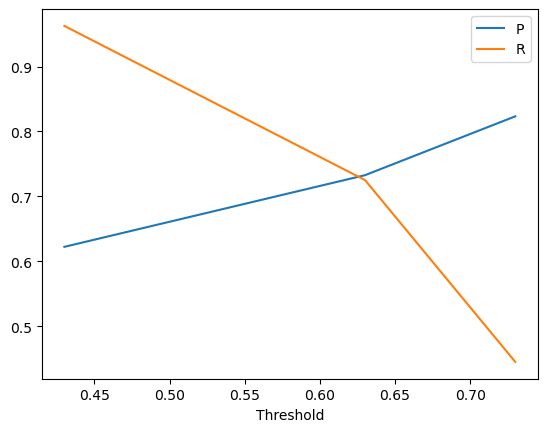

In [52]:
df_scores_mini = df_scores.loc[df_scores["threshold"].isin([0.43,0.63,0.73,0.83])]
plt.plot(df_scores_mini.threshold, df_scores_mini['p'], label='P')
plt.plot(df_scores_mini.threshold, df_scores_mini['r'], label='R')
plt.xlabel("Threshold")
plt.legend()

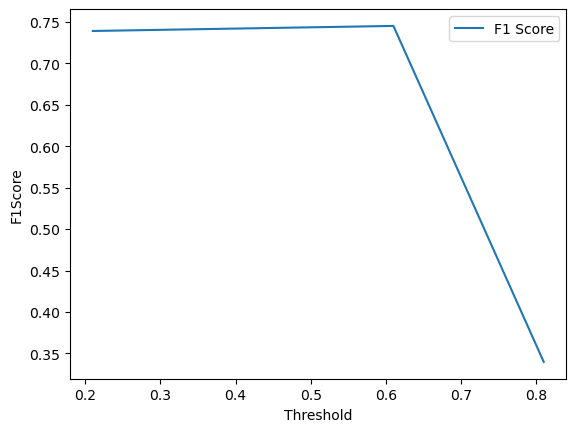

In [54]:
df_scores_mini = df_scores.loc[df_scores["threshold"].isin([0.21,0.41,0.61,0.81])]
plt.plot(df_scores_mini.threshold, df_scores_mini['f1'], label='F1 Score')
plt.xlabel("Threshold")
plt.ylabel("F1Score")
plt.legend()

Question 5: 5-Fold CV
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)
Iterate over different folds of df_full_train
Split the data into train and validation
Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
Use AUC to evaluate the model on validation
How large is standard deviation of the scores across different folds?

0.001
0.007
0.013
0.060

In [67]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical_iv].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [68]:
dv, model = train(df_train, y_train, C=1)

In [69]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [70]:
y_pred = predict(df_val, dv, model)

In [71]:
from sklearn.model_selection import KFold

In [72]:
from tqdm.auto import tqdm

In [75]:
n_splits = 5

for C in tqdm([1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values
        

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s : %.3f : +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/1 [00:00<?, ?it/s]

C=1 : 0.732 : +- 0.007


In [77]:
n_splits = 5

for C in tqdm([0.000001, 0.001, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values
        

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s : roc_score =  %.3f : std =  +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 : roc_score =  0.617 : std =  +- 0.019
C=0.001 : roc_score =  0.749 : std =  +- 0.010
C=1 : roc_score =  0.732 : std =  +- 0.007
